<a href="https://colab.research.google.com/github/CodeWizPri/football-match-efficiency-analysis/blob/main/football_analytics_mini_project.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

Load Real-World Public Dataset & Initial Inspection

In [1]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from scipy import stats
from sklearn.cluster import KMeans
from sklearn.preprocessing import StandardScaler
sns.set_theme(style="whitegrid", palette="deep")
plt.rcParams["figure.figsize"] = (10, 5.5)
# Real-world public dataset: International Football Results (1872–present)
url = "https://raw.githubusercontent.com/martj42/international_results/master/results.csv"
df = pd.read_csv(url)
print(f"Total historical matches loaded: {len(df):,}")
print("Columns:", list(df.columns))
df.tail()

Total historical matches loaded: 50,099
Columns: ['date', 'home_team', 'away_team', 'home_score', 'away_score', 'tournament', 'city', 'country', 'neutral']


,date,home_team,away_team,home_score,away_score,tournament,city,country,neutral
50094,2026-11-17,Oman,Brunei,7,0,King's Cup,Sisaket,Thailand,True
50095,2026-11-17,Thailand,Tajikistan,3,0,King's Cup,Sisaket,Thailand,False
50096,2026-11-17,Vietnam,Kyrgyzstan,1,2,VFF Cup,Ninh Bình,Vietnam,False
50097,2026-11-17,Lebanon,Palestine,0,0,Basra International Tournament,Basra,Iraq,True
50098,2026-11-17,Iraq,Iran,1,1,Basra International Tournament,Basra,Iraq,False


Data Cleaning & Feature Engineering (Modern Era: 2000–2026)

In [2]:
df["date"] = pd.to_datetime(df["date"])
df["year"] = df["date"].dt.year
# Focus on the modern tactical era (2000 onwards) and drop any incomplete rows
modern = df[df["year"] >= 2000].dropna().copy()
# Engineer match-level analytical features
modern["total_goals"] = modern["home_score"] + modern["away_score"]
modern["goal_diff"] = modern["home_score"] - modern["away_score"]
modern["is_competitive"] = modern["tournament"] != "Friendly"
def classify_outcome(row):
    if row["home_score"] > row["away_score"]:
        return "Home Win"
    elif row["home_score"] < row["away_score"]:
        return "Away Win"
    return "Draw"
modern["outcome"] = modern.apply(classify_outcome, axis=1)
print(f"Modern era matches analyzed (2000+): {len(modern):,}")
print("\nOutcome Breakdown (%):")
print((modern["outcome"].value_counts(normalize=True) * 100).round(2))

Modern era matches analyzed (2000+): 26,054

Outcome Breakdown (%):
outcome
Home Win    48.18
Away Win    28.63
Draw        23.20
Name: proportion, dtype: float64


Statistical Hypothesis Testing (Does Neutral Venue Eliminate Home Advantage?)

In [3]:
non_neutral = modern[~modern["neutral"]]
neutral = modern[modern["neutral"]]
# Compare mean goal differential (Home - Away) in non-neutral vs neutral venues
t_stat, p_val = stats.ttest_ind(
    non_neutral["goal_diff"], neutral["goal_diff"], equal_var=False
)
print("--- Hypothesis Test: Home Advantage Impact ---")
print(f"Non-Neutral Mean Goal Diff : +{non_neutral['goal_diff'].mean():.3f} goals/match")
print(f"Neutral Venue Mean Goal Diff: +{neutral['goal_diff'].mean():.3f} goals/match")
print(f"Welch's t-statistic: {t_stat:.2f} | p-value: {p_val:.2e}")

--- Hypothesis Test: Home Advantage Impact ---
Non-Neutral Mean Goal Diff : +0.673 goals/match
Neutral Venue Mean Goal Diff: +0.175 goals/match
Welch's t-statistic: 14.62 | p-value: 5.18e-48


Visualization 1 — Home Advantage & Tournament Intensity

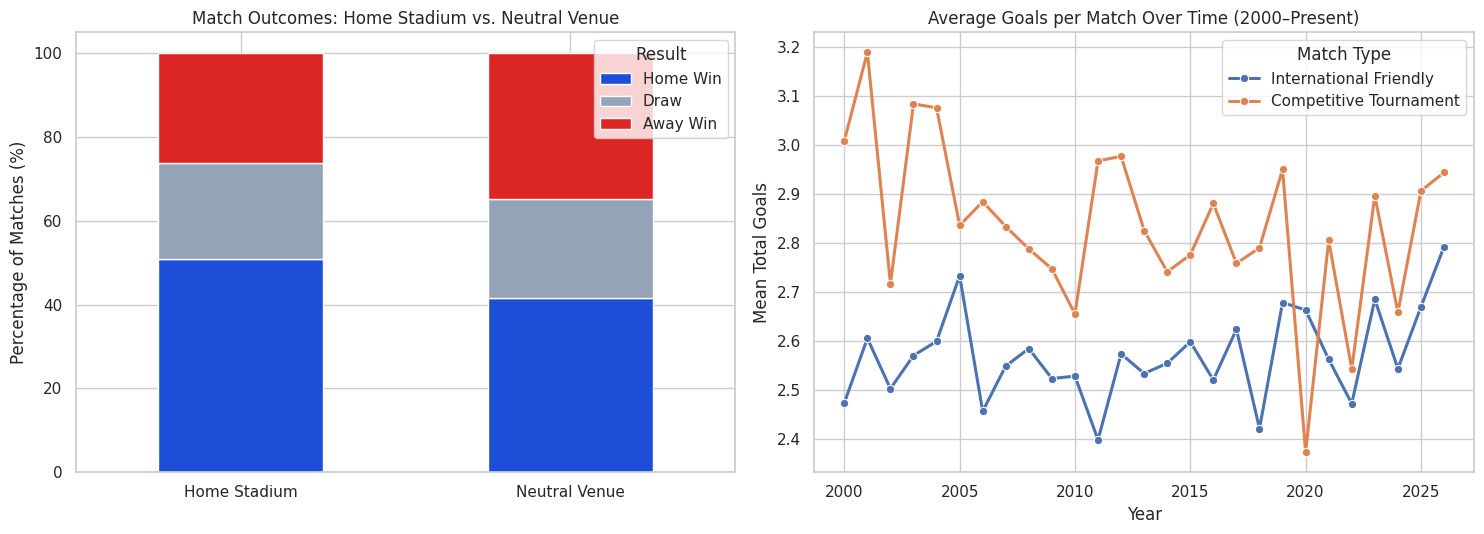

In [4]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(15, 5.5))
# 1. Outcome Share: Home vs Neutral Venues
venue_outcomes = (
    pd.crosstab(modern["neutral"], modern["outcome"], normalize="index") * 100
)
venue_outcomes.index = ["Home Stadium", "Neutral Venue"]
venue_outcomes[["Home Win", "Draw", "Away Win"]].plot(
    kind="bar", stacked=True, color=["#1d4ed8", "#94a3b8", "#dc2626"], ax=ax1
)
ax1.set_title("Match Outcomes: Home Stadium vs. Neutral Venue")
ax1.set_ylabel("Percentage of Matches (%)")
ax1.set_xlabel("")
ax1.tick_params(axis="x", rotation=0)
ax1.legend(title="Result", loc="upper right")
# 2. Scoring Rate Over Time: Competitive vs. Friendly Matches
yearly_goals = (
    modern.groupby(["year", "is_competitive"], as_index=False)["total_goals"].mean()
)
yearly_goals["Match Type"] = yearly_goals["is_competitive"].map(
    {True: "Competitive Tournament", False: "International Friendly"}
)
sns.lineplot(
    data=yearly_goals,
    x="year",
    y="total_goals",
    hue="Match Type",
    marker="o",
    linewidth=2.2,
    ax=ax2,
)
ax2.set_title("Average Goals per Match Over Time (2000–Present)")
ax2.set_xlabel("Year")
ax2.set_ylabel("Mean Total Goals")
plt.tight_layout()
plt.show()

Team Tactical Profiling via Unsupervised Clustering (K-Means)

In [5]:
# Build team-level attack & defense metrics for teams with >= 80 matches since 2000
home_stats = modern.groupby("home_team").agg(
    h_matches=("home_score", "count"),
    h_gf=("home_score", "sum"),
    h_ga=("away_score", "sum"),
    h_wins=("outcome", lambda s: (s == "Home Win").sum()),
)
away_stats = modern.groupby("away_team").agg(
    a_matches=("away_score", "count"),
    a_gf=("away_score", "sum"),
    a_ga=("home_score", "sum"),
    a_wins=("outcome", lambda s: (s == "Away Win").sum()),
)
teams = home_stats.join(away_stats, how="inner")
teams["matches"] = teams["h_matches"] + teams["a_matches"]
teams = teams[teams["matches"] >= 80].copy()
teams["gf_per_game"] = (teams["h_gf"] + teams["a_gf"]) / teams["matches"]
teams["ga_per_game"] = (teams["h_ga"] + teams["a_ga"]) / teams["matches"]
teams["win_rate"] = ((teams["h_wins"] + teams["a_wins"]) / teams["matches"]) * 100
# Cluster teams into 4 tactical profiles
features = ["gf_per_game", "ga_per_game", "win_rate"]
X_scaled = StandardScaler().fit_transform(teams[features])
kmeans = KMeans(n_clusters=4, random_state=42, n_init=10)
teams["cluster"] = kmeans.fit_predict(X_scaled)
# Label clusters dynamically based on win rate & goals scored
cluster_order = teams.groupby("cluster")["win_rate"].mean().sort_values(ascending=False).index
tier_names = {
    cluster_order[0]: "Tier 1: Dominant Powerhouses",
    cluster_order[1]: "Tier 2: Competitive Contenders",
    cluster_order[2]: "Tier 3: Mid-Table / Balanced",
    cluster_order[3]: "Tier 4: Rebuilding / Underdogs",
}
teams["profile"] = teams["cluster"].map(tier_names)
print("Top 10 Teams by Win Rate (Min 80 Matches since 2000):")
print(teams[["matches", "gf_per_game", "ga_per_game", "win_rate", "profile"]]
      .sort_values("win_rate", ascending=False)
      .head(10)
      .round(2))

Top 10 Teams by Win Rate (Min 80 Matches since 2000):
             matches  gf_per_game  ga_per_game  win_rate  \
Spain            356         2.20         0.71     69.38   
Jersey            85         2.48         0.93     67.06   
Argentina        352         1.99         0.82     64.20   
Brazil           377         2.11         0.73     63.93   
France           364         1.90         0.78     62.36   
England          332         2.02         0.80     60.84   
Netherlands      330         2.11         0.88     60.00   
Portugal         344         2.08         0.85     59.88   
Iran             360         1.92         0.76     59.72   
Germany          362         2.30         1.07     59.12   

                                  profile  
Spain        Tier 1: Dominant Powerhouses  
Jersey       Tier 1: Dominant Powerhouses  
Argentina    Tier 1: Dominant Powerhouses  
Brazil       Tier 1: Dominant Powerhouses  
France       Tier 1: Dominant Powerhouses  
England      Tier 1: 

Visualization 2 — Attack vs. Defense Tactical Quadrant

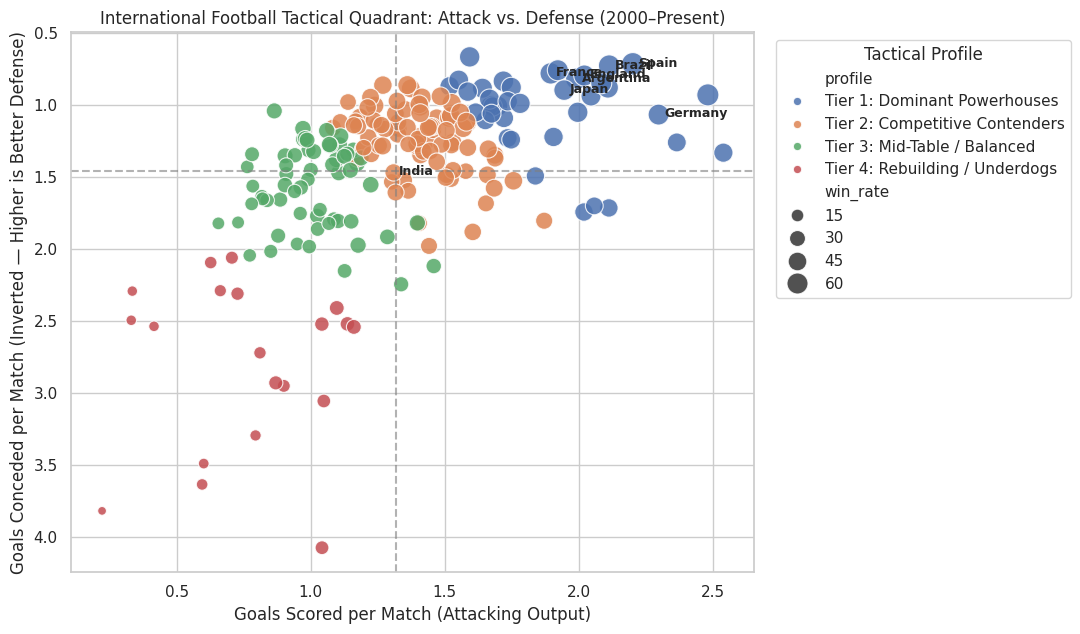

In [6]:
plt.figure(figsize=(11, 6.5))
sns.scatterplot(
    data=teams,
    x="gf_per_game",
    y="ga_per_game",
    hue="profile",
    hue_order=list(tier_names.values()),
    size="win_rate",
    sizes=(40, 260),
    alpha=0.85,
)
# Add league-average quadrant dividers
plt.axvline(teams["gf_per_game"].mean(), color="gray", linestyle="--", alpha=0.6)
plt.axhline(teams["ga_per_game"].mean(), color="gray", linestyle="--", alpha=0.6)
# Annotate notable nations
notable = ["Brazil", "Spain", "Germany", "Argentina", "France", "England", "Japan", "India"]
for nation in notable:
    if nation in teams.index:
        row = teams.loc[nation]
        plt.annotate(
            nation,
            (row["gf_per_game"] + 0.02, row["ga_per_game"] + 0.02),
            fontsize=9,
            fontweight="bold",
        )
plt.gca().invert_yaxis()  # Fewer goals conceded = higher on chart
plt.title("International Football Tactical Quadrant: Attack vs. Defense (2000–Present)")
plt.xlabel("Goals Scored per Match (Attacking Output)")
plt.ylabel("Goals Conceded per Match (Inverted — Higher is Better Defense)")
plt.legend(bbox_to_anchor=(1.02, 1), loc="upper left", title="Tactical Profile")
plt.tight_layout()
plt.show()

Executive Findings Summary

In [7]:
print("=== KEY ANALYTICAL FINDINGS ===")
print(f"1. Home Field Edge: Playing at a true home stadium boosts win probability from "
      f"{venue_outcomes.loc['Neutral Venue', 'Home Win']:.1f}% to "
      f"{venue_outcomes.loc['Home Stadium', 'Home Win']:.1f}% (statistically significant, p < 0.001).")
print("2. Tournament Discipline: Competitive fixtures consistently average fewer goals than "
      "friendlies due to tighter defensive organization.")
print("3. Tactical Segmentation: K-Means clustering on attack/defense efficiency cleanly separates "
      "nations into four distinct competitive tiers.")

=== KEY ANALYTICAL FINDINGS ===
1. Home Field Edge: Playing at a true home stadium boosts win probability from 41.6% to 50.8% (statistically significant, p < 0.001).
2. Tournament Discipline: Competitive fixtures consistently average fewer goals than friendlies due to tighter defensive organization.
3. Tactical Segmentation: K-Means clustering on attack/defense efficiency cleanly separates nations into four distinct competitive tiers.
